# Day 06 — Feature Scaling
## Holistic Data Preparer | Customer Credit Risk Prediction

## 1. Feature scaling: concept

Feature scaling transforms numerical predictors to comparable scales. Credit-risk data may contain income, loan amount, credit score, transaction count, and ratios measured in very different units.

Algorithms such as KNN, SVM, regularized Logistic Regression, and neural networks can be sensitive to feature magnitude. Tree-based models generally do not require scaling.

## 2. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler, RobustScaler
import joblib

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

## 3. Load the prepared Day 05 dataset

In [2]:
DATA_PATH = Path("../data/interim/customer_credit_risk_encoded.csv")

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
    DATA_SOURCE = "Day 05 prepared project dataset"
else:
    rng = np.random.default_rng(RANDOM_STATE)
    n = 1000
    df = pd.DataFrame({
        "customer_id": [f"CUST{i:05d}" for i in range(1, n + 1)],
        "age": rng.integers(21, 66, n),
        "annual_income": rng.lognormal(11, 0.55, n).round(2),
        "loan_amount": rng.lognormal(10, 0.60, n).round(2),
        "credit_score": rng.integers(300, 851, n),
        "transaction_count": rng.poisson(35, n),
        "spending_ratio": rng.uniform(0.05, 1.20, n).round(4),
        "default_flag": rng.binomial(1, 0.18, n)
    })
    DATA_SOURCE = "Synthetic demonstration data"

print("Data source:", DATA_SOURCE)
print("Shape:", df.shape)
display(df.head())

Data source: Synthetic demonstration data
Shape: (1000, 8)


,customer_id,age,annual_income,loan_amount,credit_score,transaction_count,spending_ratio,default_flag
0,CUST00001,25,131698.17,30883.82,800,39,0.2507,0
1,CUST00002,55,62965.11,23594.07,622,37,1.1214,0
2,CUST00003,50,82407.14,26848.52,396,45,0.6600,0
3,CUST00004,40,58033.12,35121.39,730,34,0.2550,0
4,CUST00005,40,54517.43,13552.25,378,37,0.7928,0


## 4. Identify numerical predictor columns

In [3]:
TARGET = "default_flag"
ID_COLUMNS = ["customer_id", "id", "loan_id"]

numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
feature_columns = [c for c in numeric_columns if c != TARGET and c not in ID_COLUMNS]

if not feature_columns:
    raise ValueError("No numerical predictor columns found.")

print("Features to scale:", feature_columns)
display(df[feature_columns].describe().T)

Features to scale: ['age', 'annual_income', 'loan_amount', 'credit_score', 'transaction_count', 'spending_ratio']


,count,mean,std,min,25%,50%,75%,max
age,1000.0,43.141000,12.997463,21.0000,32.0000,43.0000,55.000000,65.0000
annual_income,1000.0,69021.351560,40505.467368,8049.5600,41045.4250,59987.9450,84937.012500,343990.5700
loan_amount,1000.0,25108.604390,16795.517098,3504.2500,14009.6475,21597.0150,31257.795000,126569.4900
credit_score,1000.0,572.411000,154.359084,300.0000,437.7500,574.0000,707.000000,850.0000
transaction_count,1000.0,34.668000,5.762550,15.0000,31.0000,34.0000,38.000000,53.0000
spending_ratio,1000.0,0.613089,0.331622,0.0504,0.3107,0.6191,0.898875,1.1987


## 5. Check missing values

In [4]:
missing = df[feature_columns].isna().sum().to_frame("missing_count")
missing["missing_percent"] = missing["missing_count"] / len(df) * 100
display(missing)

if df[feature_columns].isna().any().any():
    raise ValueError("Missing values remain. Complete Day 03 imputation before scaling.")

,missing_count,missing_percent
age,0,0.0
annual_income,0,0.0
loan_amount,0,0.0
credit_score,0,0.0
transaction_count,0,0.0
spending_ratio,0,0.0


## 6. Inspect original distributions

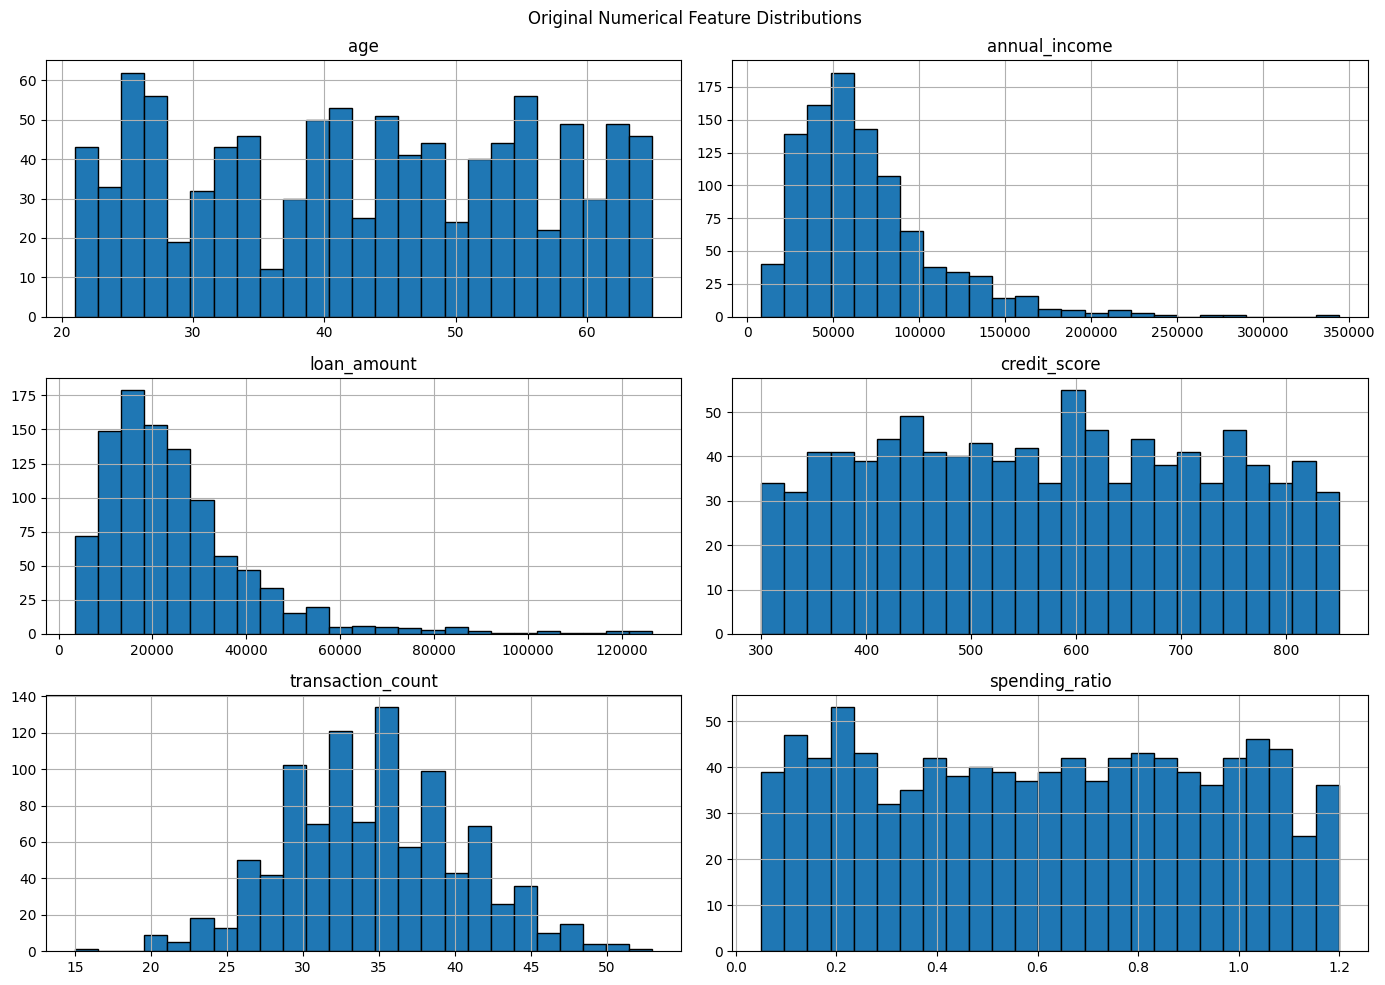

In [5]:
df[feature_columns].hist(figsize=(14, 10), bins=25, edgecolor="black")
plt.suptitle("Original Numerical Feature Distributions")
plt.tight_layout()
plt.show()

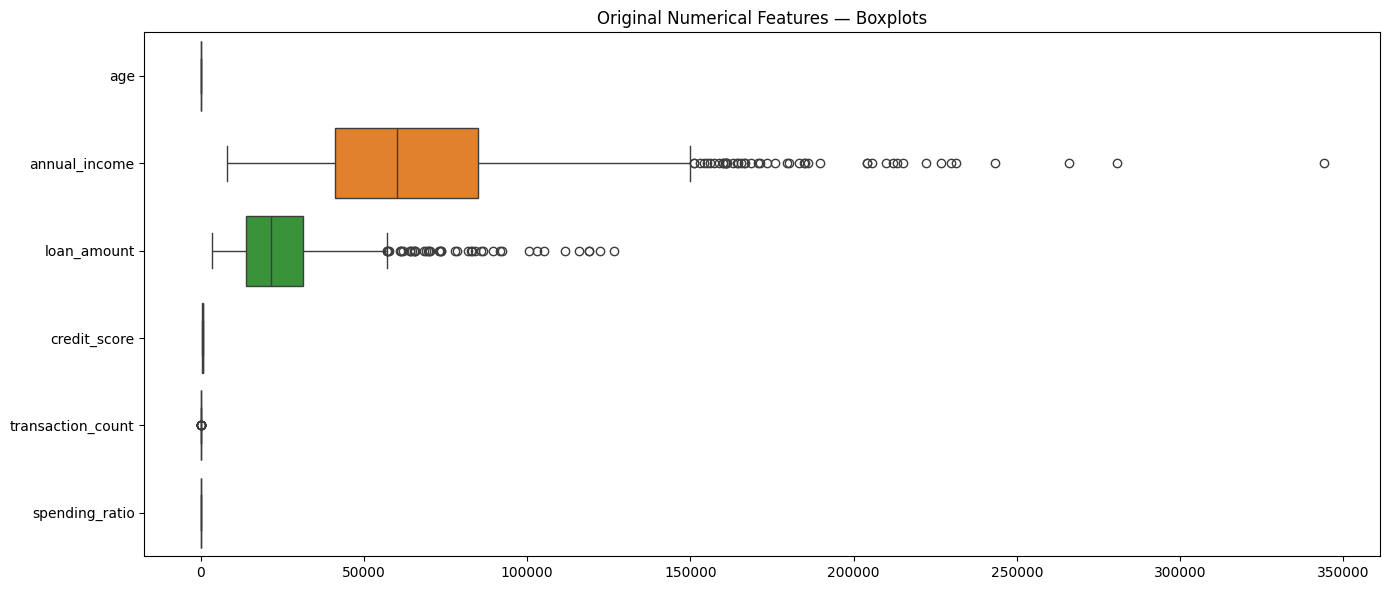

In [6]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=df[feature_columns], orient="h")
plt.title("Original Numerical Features — Boxplots")
plt.tight_layout()
plt.show()

## 7. Split before fitting scalers

In [7]:
X = df[feature_columns].copy()
y = df[TARGET].copy() if TARGET in df.columns else None

if y is not None and y.nunique() > 1:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
    )
else:
    X_train, X_test = train_test_split(
        X, test_size=0.20, random_state=RANDOM_STATE
    )

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (800, 6)
Testing shape: (200, 6)


## 8. StandardScaler — standardization

In [8]:
standard_scaler = StandardScaler()
X_train_standard = pd.DataFrame(
    standard_scaler.fit_transform(X_train), columns=feature_columns, index=X_train.index
)
X_test_standard = pd.DataFrame(
    standard_scaler.transform(X_test), columns=feature_columns, index=X_test.index
)
display(X_train_standard.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,800.0,-1.310063e-16,1.000626,-1.693306,-0.868753,-0.005849,0.914583,1.681609
annual_income,800.0,1.709743e-16,1.000626,-1.490884,-0.705594,-0.224895,0.395819,6.663765
loan_amount,800.0,-5.440093e-17,1.000626,-1.271532,-0.662606,-0.214200,0.350372,5.920339
credit_score,800.0,3.641532e-16,1.000626,-1.774769,-0.875140,0.030961,0.872341,1.778442
transaction_count,800.0,-1.909584e-16,1.000626,-3.398415,-0.649444,0.037798,0.725041,2.786769
spending_ratio,800.0,-1.021405e-16,1.000626,-1.713901,-0.877784,0.023218,0.836260,1.784098


## 9. MinMaxScaler — min-max scaling

In [9]:
minmax_scaler = MinMaxScaler()
X_train_minmax = pd.DataFrame(
    minmax_scaler.fit_transform(X_train), columns=feature_columns, index=X_train.index
)
X_test_minmax = pd.DataFrame(
    minmax_scaler.transform(X_test), columns=feature_columns, index=X_test.index
)
display(X_train_minmax.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,800.0,0.501733,0.296489,0.0,0.244318,0.500000,0.772727,1.0
annual_income,800.0,0.182826,0.122706,0.0,0.096300,0.155248,0.231365,1.0
loan_amount,800.0,0.176801,0.139133,0.0,0.084669,0.147018,0.225519,1.0
credit_score,800.0,0.499483,0.281612,0.0,0.253188,0.508197,0.744991,1.0
transaction_count,800.0,0.549444,0.161778,0.0,0.444444,0.555556,0.666667,1.0
spending_ratio,800.0,0.489966,0.286057,0.0,0.239027,0.496604,0.729034,1.0


## 10. MaxAbsScaler

In [10]:
maxabs_scaler = MaxAbsScaler()
X_train_maxabs = pd.DataFrame(
    maxabs_scaler.fit_transform(X_train), columns=feature_columns, index=X_train.index
)
X_test_maxabs = pd.DataFrame(
    maxabs_scaler.transform(X_test), columns=feature_columns, index=X_test.index
)
display(X_train_maxabs.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,800.0,0.662712,0.200700,0.323077,0.488462,0.661538,0.846154,1.0
annual_income,800.0,0.201949,0.119835,0.023401,0.117447,0.175015,0.249352,1.0
loan_amount,800.0,0.199593,0.135281,0.027686,0.110011,0.170634,0.246962,1.0
credit_score,800.0,0.676725,0.181888,0.354118,0.517647,0.682353,0.835294,1.0
transaction_count,800.0,0.681961,0.114196,0.294118,0.607843,0.686275,0.764706,1.0
spending_ratio,800.0,0.511411,0.274029,0.042046,0.271023,0.517769,0.740427,1.0


## 11. RobustScaler

In [11]:
robust_scaler = RobustScaler()
X_train_robust = pd.DataFrame(
    robust_scaler.fit_transform(X_train), columns=feature_columns, index=X_train.index
)
X_test_robust = pd.DataFrame(
    robust_scaler.transform(X_test), columns=feature_columns, index=X_test.index
)
display(X_train_robust.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,800.0,0.003280,0.561098,-0.946237,-0.483871,0.000000e+00,0.516129,0.946237
annual_income,800.0,0.204188,0.908492,-1.149422,-0.436438,-8.023096e-17,0.563562,6.254380
loan_amount,800.0,0.211455,0.987807,-1.043786,-0.442662,1.049508e-16,0.557338,6.055948
credit_score,800.0,-0.017718,0.572610,-1.033333,-0.518519,0.000000e+00,0.481481,1.000000
transaction_count,800.0,-0.027500,0.728000,-2.500000,-0.500000,0.000000e+00,0.500000,2.000000
spending_ratio,800.0,-0.013546,0.583781,-1.013462,-0.525659,9.887924e-17,0.474341,1.027325


## 12. Compare scaling methods

In [12]:
scaled_versions = {
    "Original": X_train,
    "StandardScaler": X_train_standard,
    "MinMaxScaler": X_train_minmax,
    "MaxAbsScaler": X_train_maxabs,
    "RobustScaler": X_train_robust
}

rows = []
for method, scaled_df in scaled_versions.items():
    for col in feature_columns:
        rows.append({
            "method": method, "feature": col,
            "mean": scaled_df[col].mean(),
            "std": scaled_df[col].std(),
            "min": scaled_df[col].min(),
            "median": scaled_df[col].median(),
            "max": scaled_df[col].max()
        })
comparison = pd.DataFrame(rows)
display(comparison.round(4))

,method,feature,mean,std,min,median,max
0,Original,age,43.0762,13.0455,21.0000,43.0000,65.0000
1,Original,annual_income,69468.4081,41222.0283,8049.5600,60203.5650,343990.5700
2,Original,loan_amount,25262.3369,17122.4206,3504.2500,21597.0150,126569.4900
3,Original,credit_score,575.2162,154.6048,301.0000,580.0000,850.0000
4,Original,transaction_count,34.7800,5.8240,15.0000,35.0000,51.0000
5,Original,spending_ratio,0.6130,0.3285,0.0504,0.6206,1.1987
6,StandardScaler,age,-0.0000,1.0006,-1.6933,-0.0058,1.6816
7,StandardScaler,annual_income,0.0000,1.0006,-1.4909,-0.2249,6.6638
8,StandardScaler,loan_amount,-0.0000,1.0006,-1.2715,-0.2142,5.9203
9,StandardScaler,credit_score,0.0000,1.0006,-1.7748,0.0310,1.7784


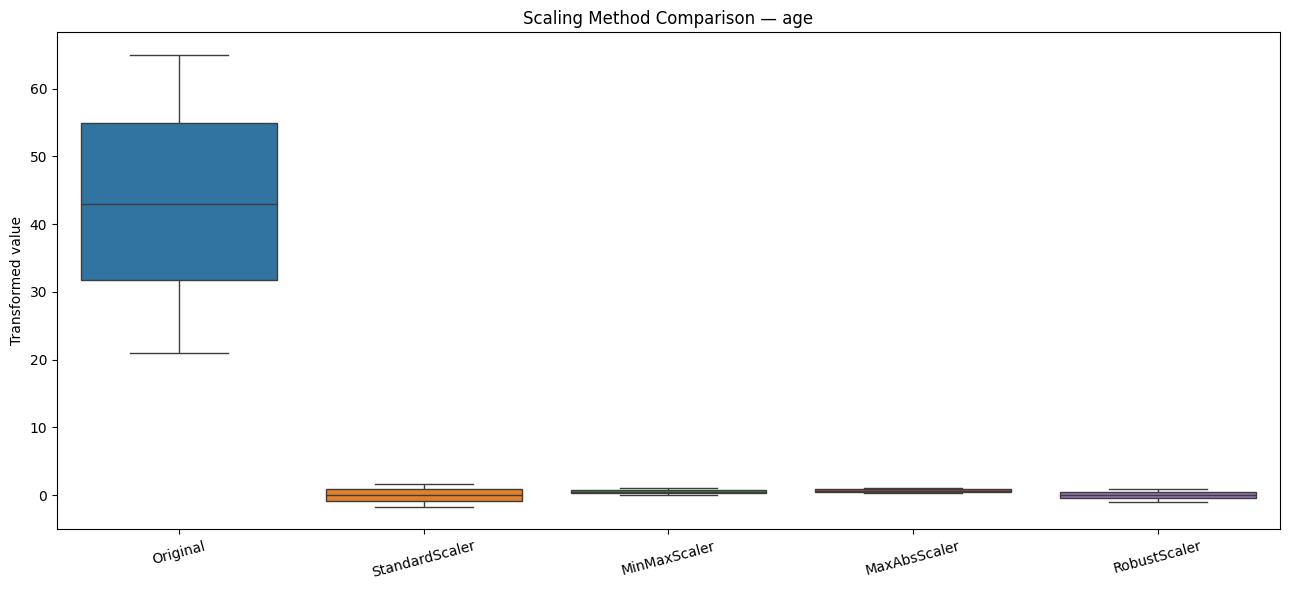

In [13]:
feature_to_plot = feature_columns[0]
plot_data = pd.DataFrame({
    "Original": X_train[feature_to_plot].reset_index(drop=True),
    "StandardScaler": X_train_standard[feature_to_plot].reset_index(drop=True),
    "MinMaxScaler": X_train_minmax[feature_to_plot].reset_index(drop=True),
    "MaxAbsScaler": X_train_maxabs[feature_to_plot].reset_index(drop=True),
    "RobustScaler": X_train_robust[feature_to_plot].reset_index(drop=True)
})
plt.figure(figsize=(13, 6))
sns.boxplot(data=plot_data)
plt.title(f"Scaling Method Comparison — {feature_to_plot}")
plt.ylabel("Transformed value")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 13. Scaler selection guide

| Scaler | Main behaviour | When to consider |
|---|---|---|
| StandardScaler | Mean 0, standard deviation 1 | General baseline for scale-sensitive algorithms |
| MinMaxScaler | Fixed training range, usually [0, 1] | Bounded inputs are useful and outliers are controlled |
| MaxAbsScaler | Divides by maximum absolute value | Sparse data; preserve zero entries |
| RobustScaler | Median and IQR | Influential outliers remain |

There is no universally best scaler. Choose using feature distributions, the downstream algorithm, and validation performance. Scaling does not remove outliers.

## 14. Prepare final scaled datasets

In [14]:
final_scaler = RobustScaler()
X_train_final = pd.DataFrame(
    final_scaler.fit_transform(X_train), columns=feature_columns, index=X_train.index
)
X_test_final = pd.DataFrame(
    final_scaler.transform(X_test), columns=feature_columns, index=X_test.index
)

train_output = X_train_final.copy()
test_output = X_test_final.copy()
if y is not None:
    train_output[TARGET] = y_train
    test_output[TARGET] = y_test

display(train_output.head())
print("Train:", train_output.shape, "| Test:", test_output.shape)

,age,annual_income,loan_amount,credit_score,transaction_count,spending_ratio,default_flag
829,-0.903226,-0.637263,0.840433,0.748148,0.000,-0.217977,0
265,0.172043,2.219740,-0.347073,-0.896296,0.125,-0.813169,0
721,0.817204,0.335849,0.095925,-0.859259,1.750,-0.144400,0
976,-0.774194,0.060268,-0.361838,-0.807407,-0.750,-0.735327,1
922,-0.086022,-0.319910,-0.409799,0.644444,1.000,-0.596348,0


Train: (800, 7) | Test: (200, 7)


## 15. Save processed outputs

In [15]:
OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

train_output.to_csv(OUTPUT_DIR / "customer_credit_risk_train_scaled.csv", index=False)
test_output.to_csv(OUTPUT_DIR / "customer_credit_risk_test_scaled.csv", index=False)
joblib.dump(final_scaler, OUTPUT_DIR / "robust_scaler.joblib")

print("Scaled datasets and fitted scaler saved to:", OUTPUT_DIR.resolve())

Scaled datasets and fitted scaler saved to: C:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer\data\processed


## 16. Validation checks

In [16]:
assert list(X_train_final.columns) == list(X_test_final.columns)
assert TARGET not in X_train_final.columns
assert TARGET not in X_test_final.columns
assert len(train_output) == len(X_train)
assert len(test_output) == len(X_test)
print("All validation checks passed.")

All validation checks passed.


### Conclusion
Feature scaling makes numerical predictors comparable for algorithms sensitive to feature magnitude. Fit the scaler on training data only and transform the test data using the same fitted scaler. Select the final method based on dataset characteristics and model-validation results.